# Paso 6 · Redes neuronales (MLP, CNN 1D, GRU e híbrido) con TensorFlow/Keras

| | |
|---|---|
| **IDs del enunciado** | IA3.2 (redes CNN/RNN en TensorFlow/Keras), IA3.E2 (entrenar y evaluar una red), IA3.3 (clásicos vs Deep Learning), F3 |
| **Fase** | F3 · Analizar y modelar (CRISP-DM: *Modeling*) |
| **Historia** | HU-06 · Sprint S6 |
| **Entregable** | este notebook + `Back/models/red_neuronal.keras` + `Back/models/resultados_dl.json` |

**Objetivo.** Entrenar cuatro redes sobre el mismo problema que los modelos clásicos del paso 5: un
**MLP** de referencia y una **CNN 1D** sobre las variables tabulares, una **RNN (GRU bidireccional)** sobre el
texto de la solicitud y un **híbrido** texto + tabular con la API funcional de Keras. Se evalúan en test con
**las mismas métricas y el mismo umbral** del paso 5 y se comparan con los clásicos en desempeño, tiempo e
interpretabilidad.

**Aprendizaje de la unidad (Módulo 2 · Unidad 3).**
- *Conceptual:* una red aprende representaciones por capas; su capacidad la hace propensa al
  **sobreajuste**, que se diagnostica con las **curvas de aprendizaje** (train vs validación) y se controla con
  *Dropout*, *BatchNormalization* y *EarlyStopping*. Cada arquitectura trae un **sesgo inductivo**: la CNN
  supone patrones locales (vecindad), la RNN supone orden secuencial. Que encajen o no con los datos explica
  buena parte del resultado.
- *Práctico:* Keras 3 sobre TensorFlow (`Sequential`/API funcional, `TextVectorization`, `class_weight`,
  `EarlyStopping`, `ModelCheckpoint`, métricas `AUC`/`Precision`/`Recall`), separación de un conjunto de
  validación **desde train**, preprocesamiento ajustado solo con datos de ajuste y guardado en formato `.keras`.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup
from credit_risk.dl import keras_tf

keras = keras_tf()  # TensorFlow se carga ANTES que scikit-learn: en Windows el orden inverso rompe su DLL
ENTORNO = setup(paquetes=["pandas", "numpy", "matplotlib", "scikit-learn", "tensorflow", "keras"])
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'scikit-learn': '1.4.2',
  'tensorflow': '2.20.0',
  'keras': '3.12.4'}}

In [4]:
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split

from credit_risk import config, dl
from credit_risk.data import cargar_procesados, separar_xy
from credit_risk.models import curvas, metricas, umbrales_chow
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, SERIE, figura_front, leer_json
from credit_risk.schemas_resultados import FilaModelo, Metricas, ResultadosDL, guardar_resultados

train, test = cargar_procesados()
X_train, y_train = separar_xy(train)
X_te, y_te = separar_xy(test)
if FAST:
    X_train, y_train = X_train.iloc[:2000], y_train[:2000]
# Validación separada DESDE train (estratificada, semilla fija); test no se toca hasta la sección 6.
X_fit, X_va, y_fit, y_va = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                            random_state=config.RANDOM_STATE)
UMBRAL = umbrales_chow().bayes
PREVALENCIA = float(y_fit.mean())
EPOCAS, PACIENCIA, LOTE = (4, 2, 128) if FAST else (30, 5, 256)
pd.DataFrame({"filas": [len(y_fit), len(y_va), len(y_te)],
              "tasa_impago": [y_fit.mean(), y_va.mean(), y_te.mean()]},
             index=["ajuste (80 % de train)", "validación (20 % de train)", "test"])

,filas,tasa_impago
ajuste (80 % de train),7680,0.3556
validación (20 % de train),1920,0.3557
test,2400,0.3558


## 1. Preprocesamiento: el mismo del modelo servido, ajustado solo con la partición de ajuste

`dl.preprocesador_tabular()` es el pipeline del paso 3 sin el estimador (variables derivadas → capping
p1-p99 → imputación, escalado y *one-hot*). Se ajusta **solo** con la partición de ajuste: ni validación ni
test aportan estadísticos (medianas, medias, desviaciones, cuantiles). Para las redes de texto,
`TextVectorization` también aprende su vocabulario solo con esos textos. `class_weight` compensa el
desbalance: cada impago pesa más que cada pago, de modo que ambas clases aportan lo mismo a la pérdida.

In [5]:
pre = dl.preprocesador_tabular().fit(X_fit, y_fit)
A_fit, A_va, A_te = (pre.transform(X).astype("float32") for X in (X_fit, X_va, X_te))
T_fit, T_va, T_te = (dl.textos_entrada(X[config.TEXT_COL]) for X in (X_fit, X_va, X_te))
N_FEAT = A_fit.shape[1]
palabras = pd.Series([len(t.decode().split()) for t in T_fit.numpy().ravel()])
print(f"Matriz tabular: {N_FEAT} columnas tras el preprocesamiento (ajuste {A_fit.shape}, test {A_te.shape})")
print(f"Textos de ajuste: {len(palabras):,} · vacíos {(palabras == 0).mean():.1%} · "
      f"palabras por texto: mediana {palabras.median():.0f}, p99 {palabras.quantile(0.99):.0f}, máx. {palabras.max()}")
print("class_weight:", {k: round(v, 3) for k, v in dl.pesos_clase(y_fit).items()})

Matriz tabular: 38 columnas tras el preprocesamiento (ajuste (7680, 38), test (2400, 38))
Textos de ajuste: 7,680 · vacíos 2.0% · palabras por texto: mediana 19, p99 28, máx. 31
class_weight: {0: 0.776, 1: 1.406}


In [6]:
CHECKPOINTS = Path(tempfile.mkdtemp(prefix="nb06_checkpoints_"))
redes, entrenos, entradas = {}, {}, {}


def ajustar(nombre, modelo, X_ajuste, X_validacion, X_test):
    """Entrena con class_weight + EarlyStopping + ModelCheckpoint (credit_risk.dl.entrenar) y registra."""
    r = dl.entrenar(modelo, X_ajuste, y_fit, X_validacion, y_va, epocas=EPOCAS, paciencia=PACIENCIA,
                    batch=LOTE, checkpoint=CHECKPOINTS / f"{nombre}.keras")
    redes[nombre], entrenos[nombre], entradas[nombre] = modelo, r, X_test
    print(f"{nombre}: {r['epocas']} épocas en {r['duracion_s']:.1f} s · mejor época {r['mejor_epoca']} "
          f"· AUC de validación {r['val_auc']:.4f}")
    print(dl.arquitectura(modelo))


def graficar_curvas(nombre):
    """Curvas de aprendizaje (pérdida y AUC, train vs validación) con la mejor época marcada."""
    h, r = entrenos[nombre]["historial"], entrenos[nombre]
    ep = list(range(1, len(h["loss"]) + 1))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    paneles = [("loss", "pérdida (entropía cruzada)", "Pérdida"), ("auc", "ROC-AUC", "AUC")]
    for a, (met, titulo, eje_y) in zip(ax, paneles):
        a.plot(ep, h[met], color=SERIE[0], lw=2, label="Entrenamiento")
        a.plot(ep, h[f"val_{met}"], color=SERIE[1], lw=2, label="Validación")
        a.axvline(r["mejor_epoca"], ls="--", color=PALETA["texto_suave"], lw=1,
                  label=f"Mejor época ({r['mejor_epoca']})")
        a.set(title=f"{nombre} · {titulo} por época", xlabel="Época", ylabel=eje_y)
        a.legend(fontsize=8)
        figura_front("lineas", f"{nombre} · {titulo} por época",
                     {"series": [{"nombre": "Entrenamiento", "x": ep, "y": h[met]},
                                 {"nombre": "Validación", "x": ep, "y": h[f"val_{met}"]}],
                      "referencias": [{"eje": "x", "valor": r["mejor_epoca"], "etiqueta": "Mejor época"}]},
                     ejes={"x": "Época", "y": eje_y}, clave=f"aprendizaje_{met}_{nombre.lower()}",
                     opciones={"formato_y": "dec3"})
    plt.show()

## 2. MLP base (Dense + BatchNormalization + Dropout)

Red densa de referencia sobre la matriz tabular. *BatchNormalization* estabiliza la escala de las
activaciones y *Dropout* apaga neuronas al azar en cada paso para que la red no memorice ejemplos. La
pérdida de entrenamiento incluye `class_weight` y Dropout activo; la de validación no, así que lo que se
compara entre ambas curvas es la **tendencia**, no el nivel. El AUC no depende de los pesos de clase: es el
diagnóstico más limpio.

In [7]:
ajustar("MLP", dl.construir_mlp(N_FEAT), A_fit, A_va, A_te)

MLP: 25 épocas en 27.8 s · mejor época 20 · AUC de validación 0.8536
MLP · 4,865 parámetros entrenables y no entrenables
tabular (InputLayer) → (None, 38) · 0 parámetros
dense (Dense) → (None, 64) · 2,496 parámetros
batch_normalization (BatchNormalization) → (None, 64) · 256 parámetros
dropout (Dropout) → (None, 64) · 0 parámetros
dense_1 (Dense) → (None, 32) · 2,080 parámetros
dropout_1 (Dropout) → (None, 32) · 0 parámetros
prob_default (Dense) → (None, 1) · 33 parámetros


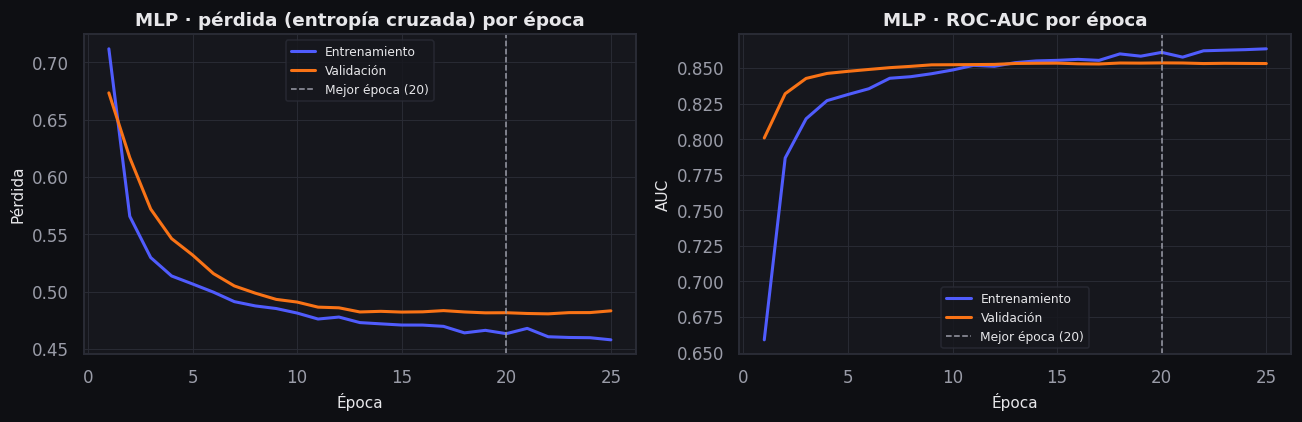

In [8]:
graficar_curvas("MLP")

**Interpretación.** La pérdida de entrenamiento baja de 0,71 a 0,46 y la de validación de 0,67 a 0,48,
donde se aplana desde la época 13 (repunta levemente al final: 0,4807 en la época 22 y 0,4834 en la 25). En
AUC, la validación sube rápido hasta 0,852 en la época 9 y luego se estanca (mejor valor 0,8536 en la época
20), mientras el entrenamiento sigue subiendo hasta 0,863: esa brecha de ≈0,01 es el **inicio de un
sobreajuste leve**, que EarlyStopping corta en la época 25 restaurando los pesos de la época 20. En las
primeras épocas el AUC de entrenamiento queda por debajo del de validación porque se calcula con Dropout
activo y promediando a lo largo de la época, mientras los pesos todavía cambian.

## 3. CNN 1D sobre el vector de características

El vector tabular se reforma a `(n_features, 1)` y se trata como una "señal" de una dimensión: filtros
`Conv1D` de tamaño 3 recorren columnas **vecinas** y `GlobalMaxPooling` resume cada filtro. El sesgo
inductivo (la vecindad importa) es artificial en datos tabulares: el orden de las columnas lo fija el
preprocesador, no el negocio. Por eso la CNN es un ejercicio de arquitectura más que una apuesta de
desempeño.

In [9]:
ajustar("CNN1D", dl.construir_cnn1d(N_FEAT), A_fit[..., None], A_va[..., None], A_te[..., None])

CNN1D: 30 épocas en 75.8 s · mejor época 30 · AUC de validación 0.7931
CNN1D · 8,577 parámetros entrenables y no entrenables
tabular_secuencia (InputLayer) → (None, 38, 1) · 0 parámetros
conv1d (Conv1D) → (None, 38, 32) · 128 parámetros
batch_normalization_1 (BatchNormalization) → (None, 38, 32) · 128 parámetros
conv1d_1 (Conv1D) → (None, 38, 64) · 6,208 parámetros
global_max_pooling1d (GlobalMaxPooling1D) → (None, 64) · 0 parámetros
dropout_2 (Dropout) → (None, 64) · 0 parámetros
dense_2 (Dense) → (None, 32) · 2,080 parámetros
prob_default (Dense) → (None, 1) · 33 parámetros


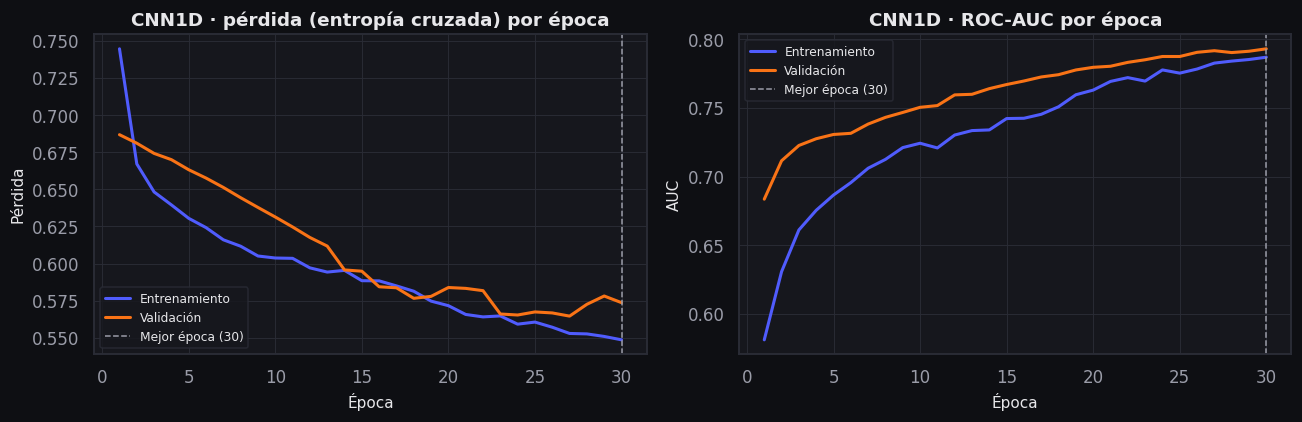

In [10]:
graficar_curvas("CNN1D")

**Interpretación.** Aquí no hay sobreajuste sino lo contrario: ambas curvas siguen mejorando al llegar al
tope de 30 épocas (la mejor época es la última, con AUC de validación 0,7931) y la validación queda por
encima del entrenamiento durante casi todo el recorrido (Dropout activo al entrenar). La red **aprende lento
y no alcanzó a converger**; al final gana alrededor de una milésima de AUC por época y su pérdida de
validación se vuelve ruidosa desde la época 15. Más épocas la acercarían algo, pero sigue lejos del MLP
(0,8536) con más parámetros (8.577 frente a 4.865). Es el costo de un sesgo inductivo que no encaja: los
filtros buscan patrones entre columnas vecinas, y en datos tabulares el orden de las columnas no significa
nada.

## 4. RNN (GRU bidireccional) sobre el texto de la solicitud

`TextVectorization` (vocabulario de hasta 3.000 términos y secuencias de 32 tokens, que cubren el texto más
largo; adaptada solo con los textos de ajuste) → `Embedding` de 32 dimensiones → `GRU` bidireccional (lee la frase en ambos sentidos) → salida sigmoide. Esta red **solo
ve el texto**: mide cuánta señal de impago contiene la redacción del solicitante. Conecta con el NLP del
paso 7.

In [11]:
ajustar("GRU_texto", dl.construir_gru_texto(T_fit), T_fit, T_va, T_te)

GRU_texto: 9 épocas en 44.6 s · mejor época 4 · AUC de validación 0.6501
GRU_texto · 108,737 parámetros entrenables y no entrenables
texto (InputLayer) → (None, 1) · 0 parámetros
vectorizar (TextVectorization) → (None, 32) · 0 parámetros
embedding (Embedding) → (None, 32, 32) · 96,000 parámetros
gru_bidireccional (Bidirectional) → (None, 64) · 12,672 parámetros
dropout_3 (Dropout) → (None, 64) · 0 parámetros
prob_default (Dense) → (None, 1) · 65 parámetros


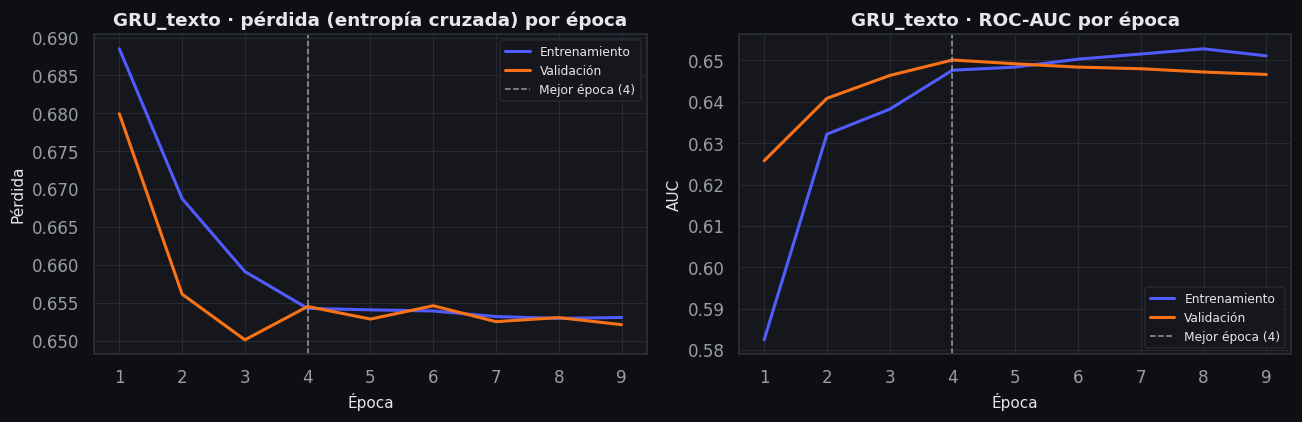

In [12]:
graficar_curvas("GRU_texto")

**Interpretación.** La GRU alcanza su mejor AUC de validación muy pronto (0,6501 en la época 4); después el
AUC de entrenamiento sigue subiendo (hasta 0,653) mientras el de validación baja poco a poco (0,6466 en la
época 9): es un **sobreajuste temprano**, y EarlyStopping detiene el entrenamiento en la época 9 y restaura
la 4. Las pérdidas apenas bajan de 0,68–0,69 a ≈0,65. Que la red, con 108.737 parámetros, ni siquiera
supere un AUC de 0,65 en su propio entrenamiento indica que el límite está en la **información del texto**,
no en la capacidad del modelo: la redacción contiene señal de impago, pero débil.

## 5. Híbrido texto + tabular (API funcional de Keras)

Dos entradas: la rama tabular (Dense + BatchNormalization + Dropout) y la rama de texto (Embedding + GRU
bidireccional) se concatenan en una capa de fusión antes de la salida. Responde si el texto agrega algo
**encima** de las variables tabulares dentro de una misma red.

In [13]:
ajustar("Hibrido", dl.construir_hibrido(N_FEAT, T_fit), {"tabular": A_fit, "texto": T_fit},
        {"tabular": A_va, "texto": T_va}, {"tabular": A_te, "texto": T_te})

Hibrido: 21 épocas en 62.2 s · mejor época 16 · AUC de validación 0.8576
Hibrido_texto_tabular · 57,153 parámetros entrenables y no entrenables
tabular (InputLayer) → (None, 38) · 0 parámetros
texto (InputLayer) → (None, 1) · 0 parámetros
dense_3 (Dense) → (None, 64) · 2,496 parámetros
vectorizar (TextVectorization) → (None, 32) · 0 parámetros
batch_normalization_2 (BatchNormalization) → (None, 64) · 256 parámetros
embedding (Embedding) → (None, 32, 16) · 48,000 parámetros
dropout_4 (Dropout) → (None, 64) · 0 parámetros
gru_bidireccional (Bidirectional) → (None, 32) · 3,264 parámetros
fusion (Concatenate) → (None, 96) · 0 parámetros
dense_4 (Dense) → (None, 32) · 3,104 parámetros
dropout_5 (Dropout) → (None, 32) · 0 parámetros
prob_default (Dense) → (None, 1) · 33 parámetros


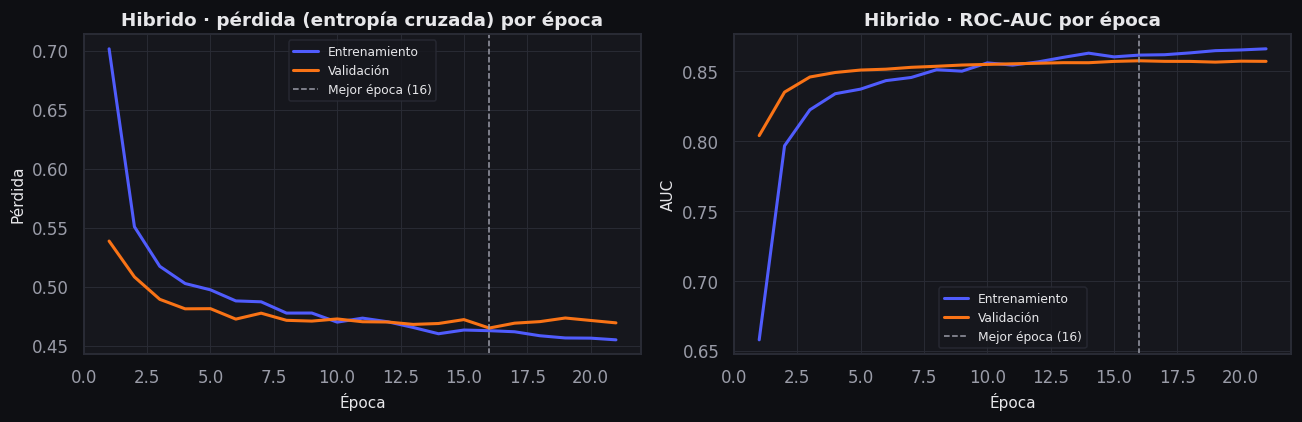

In [14]:
graficar_curvas("Hibrido")

**Interpretación.** Las curvas del híbrido se parecen a las del MLP: la validación se estanca entre 0,855 y
0,858 desde la época 10 (mejor valor 0,8576 en la época 16) mientras el entrenamiento sigue subiendo hasta
0,866, de nuevo un **sobreajuste leve** que EarlyStopping corta en la época 21. En validación supera al MLP
por 0,004 de AUC (0,8576 frente a 0,8536); la sección 6 muestra si esa ventaja se sostiene en test.

## 6. Evaluación en test con las mismas métricas del paso 5

Con `class_weight` balanceado la red aprende como si la prevalencia fuera 50 %, así que sus probabilidades
salen **infladas**. El umbral de costo 0,25 (regla de Chow) supone probabilidades calibradas, por lo que
antes de aplicarlo se deshace ese cambio de prior con `dl.corregir_prior` (corrección cerrada de las *odds*
con la prevalencia de la partición de ajuste; no usa test). La corrección es monótona: **no cambia el AUC,
el PR-AUC ni el KS**, solo el Brier y las métricas al umbral. Se muestran ambas versiones.

In [15]:
p_cruda = {n: dl.predecir(m, entradas[n]) for n, m in redes.items()}
p_test = {n: dl.corregir_prior(p, PREVALENCIA) for n, p in p_cruda.items()}
tabla_test = pd.DataFrame({n: metricas(y_te, p, UMBRAL) for n, p in p_test.items()}).T
tabla_test.insert(0, "auc_validacion", [entrenos[n]["val_auc"] for n in tabla_test.index])
tabla_test

,auc_validacion,roc_auc,pr_auc,ks,brier,accuracy,precision,recall,f1
MLP,0.8536,0.8419,0.7632,0.5353,0.1509,0.7104,0.5610,0.8560,0.6778
CNN1D,0.7931,0.7709,0.6805,0.4144,0.1795,0.5700,0.4474,0.8864,0.5947
GRU_texto,0.6501,0.6466,0.4801,0.2722,0.2128,0.4883,0.3941,0.8150,0.5313
Hibrido,0.8576,0.8399,0.7559,0.5360,0.1531,0.7196,0.5719,0.8431,0.6815


In [16]:
cruda = pd.DataFrame({n: metricas(y_te, p, UMBRAL) for n, p in p_cruda.items()}).T
pd.concat({"probabilidad cruda (class_weight)": cruda[["brier", "precision", "recall", "f1"]],
           "probabilidad corregida al prior": tabla_test[["brier", "precision", "recall", "f1"]]}, axis=1)

probabilidad cruda (class_weight)                         probabilidad corregida al prior                        
                                      brier precision recall     f1                           brier precision recall     f1
MLP                                  0.1623    0.4978 0.9087 0.6432                          0.1509    0.5610 0.8560 0.6778
CNN1D                                0.2032    0.4009 0.9660 0.5666                          0.1795    0.4474 0.8864 0.5947
GRU_texto                            0.2299    0.3558 1.0000 0.5249                          0.2128    0.3941 0.8150 0.5313
Hibrido                              0.1586    0.5119 0.9098 0.6551                          0.1531    0.5719 0.8431 0.6815

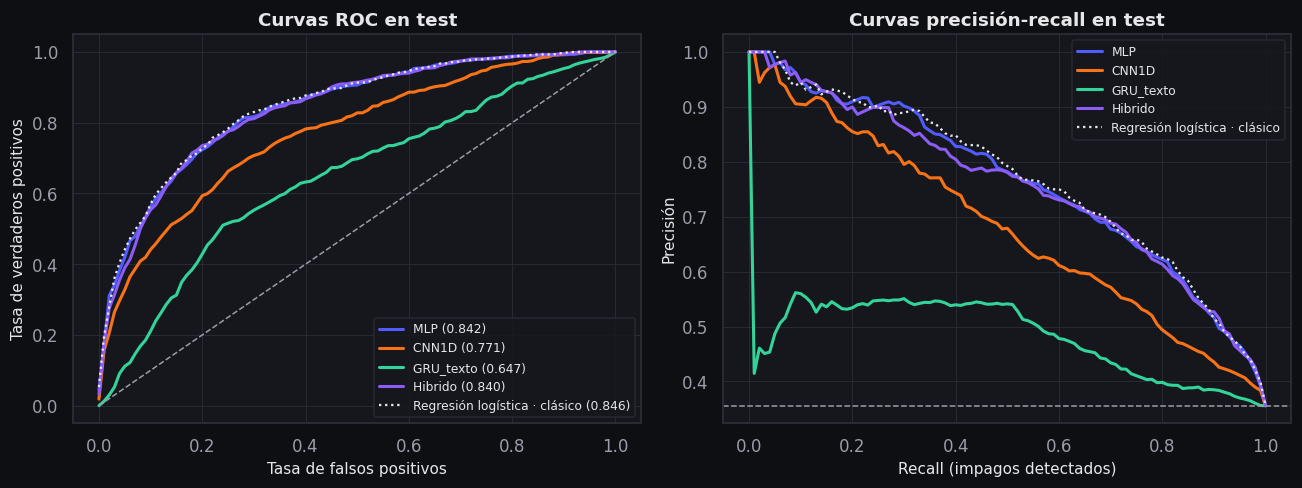

In [17]:
clasicos_path = config.MODEL_DIR / "resultados_clasicos.json"
clasicos = leer_json(clasicos_path) if clasicos_path.exists() else None
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
series_roc, series_pr = [], []
for (nombre, p), color in zip(p_test.items(), SERIE):
    c = curvas(y_te, p)
    ax[0].plot(c["fpr"], c["tpr"], color=color, lw=2, label=f"{nombre} ({tabla_test.loc[nombre, 'roc_auc']:.3f})")
    ax[1].plot(c["recall"], c["precision"], color=color, lw=2, label=nombre)
    series_roc.append({"nombre": nombre, "x": c["fpr"], "y": c["tpr"]})
    series_pr.append({"nombre": nombre, "x": c["recall"], "y": c["precision"]})
if clasicos is not None:  # referencia: el mejor clásico del paso 5 (mismo test, mismas curvas)
    ref = max((f for f in clasicos["modelos"] if f["familia"] == "clásico"), key=lambda f: f["test"]["roc_auc"])
    c = clasicos["curvas"][ref["modelo"]]
    ax[0].plot(c["fpr"], c["tpr"], color=PALETA["texto"], lw=1.5, ls=":",
               label=f"{ref['modelo']} · clásico ({ref['test']['roc_auc']:.3f})")
    ax[1].plot(c["recall"], c["precision"], color=PALETA["texto"], lw=1.5, ls=":", label=f"{ref['modelo']} · clásico")
    series_roc.append({"nombre": f"{ref['modelo']} (clásico)", "x": c["fpr"], "y": c["tpr"]})
    series_pr.append({"nombre": f"{ref['modelo']} (clásico)", "x": c["recall"], "y": c["precision"]})
ax[0].plot([0, 1], [0, 1], ls="--", color=PALETA["texto_suave"], lw=1)
ax[0].set(title="Curvas ROC en test", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax[1].axhline(y_te.mean(), ls="--", color=PALETA["texto_suave"], lw=1)
ax[1].set(title="Curvas precisión-recall en test", xlabel="Recall (impagos detectados)", ylabel="Precisión")
ax[0].legend(fontsize=8, loc="lower right")
ax[1].legend(fontsize=8, loc="upper right")
figura_front("curva_roc", "Curvas ROC en test (redes neuronales)", {"series": series_roc},
             ejes={"x": "Tasa de falsos positivos", "y": "Tasa de verdaderos positivos"}, clave="roc_test_dl",
             opciones={"formato_x": "dec3", "formato_y": "dec3"})
figura_front("curva_pr", "Curvas precisión-recall en test (redes neuronales)",
             {"series": series_pr, "referencias": [{"eje": "y", "valor": round(float(y_te.mean()), 4),
                                                    "etiqueta": "Prevalencia"}]},
             ejes={"x": "Recall (impagos detectados)", "y": "Precisión"}, clave="pr_test_dl",
             opciones={"formato_x": "dec3", "formato_y": "dec3"})
plt.show()

**Interpretación.** En test, las curvas del MLP (AUC 0,842) y del híbrido (0,840) prácticamente se superponen
con la de la regresión logística del paso 5 (punteada, 0,846): las redes no encuentran señal que el modelo
lineal no capte. La ventaja del híbrido en validación **no se sostiene en test** (queda 0,002 por debajo del
MLP), así que el texto no agrega valor robusto sobre las variables tabulares. La CNN 1D (0,771) queda
claramente por debajo, y la GRU de solo texto (0,647) supera al azar pero queda lejos del resto: en
precisión-recall ronda 0,54 de precisión hasta un recall de 0,5 y luego cae hacia la prevalencia (0,356,
línea punteada). Además, el AUC de test de cada red es entre 0,004 y 0,022 menor que su AUC de validación:
la validación se usó para detener el entrenamiento y para elegir la red, por eso resulta optimista. La
corrección del prior mejora el Brier y el F1 de las cuatro redes (tabla anterior); en la GRU, sin corregir,
todas las solicitudes quedaban por encima de 0,25 (recall 1,0).

## 7. La mejor red se guarda en `.keras`

Se elige por **AUC de validación** (test no participa en la elección). El archivo es el checkpoint que
`ModelCheckpoint` escribió en la mejor época; se recarga para comprobar que reproduce las mismas
probabilidades.

In [18]:
MEJOR = max(entrenos, key=lambda n: entrenos[n]["val_auc"])
destino = config.MODEL_DIR / "red_neuronal.keras"
destino.parent.mkdir(parents=True, exist_ok=True)
shutil.copy(CHECKPOINTS / f"{MEJOR}.keras", destino)
recargada = keras.models.load_model(destino)
dif = float(np.abs(dl.predecir(recargada, entradas[MEJOR]) - p_cruda[MEJOR]).max())
shutil.rmtree(CHECKPOINTS, ignore_errors=True)
print(f"Mejor red por AUC de validación: {MEJOR} ({entrenos[MEJOR]['val_auc']:.4f})")
print(f"Guardada en {ruta(destino)} · diferencia máxima al recargar: {dif:.2e}")

Mejor red por AUC de validación: Hibrido (0.8576)
Guardada en Back/models/red_neuronal.keras · diferencia máxima al recargar: 0.00e+00


## 8. IA3.3 · Clásicos vs Deep Learning

Se juntan las filas del paso 5 (`resultados_clasicos.json`) con las de este notebook: mismo test (2.400
filas), mismo umbral (0,25) y mismas métricas. El tiempo es el de un entrenamiento completo (en los clásicos,
el ajuste final con todo train; en las redes, el entrenamiento con *early stopping*).

In [19]:
FAMILIA_TEXTO = {"MLP": "tabular", "CNN1D": "tabular", "GRU_texto": "solo texto", "Hibrido": "texto + tabular"}
filas_dl = [FilaModelo(modelo=f"{n} (Keras)", familia="deep learning", test=Metricas(**tabla_test.loc[n].drop("auc_validacion")),
                       tiempo_entrenamiento_s=entrenos[n]["duracion_s"], interpretabilidad="baja",
                       notas=(f"Entrada {FAMILIA_TEXTO[n]}. AUC de validación {entrenos[n]['val_auc']:.4f} "
                              f"(mejor época {entrenos[n]['mejor_epoca']} de {entrenos[n]['epocas']}). "
                              f"Probabilidades corregidas al prior de train (class_weight); sin corregir: "
                              f"F1 {cruda.loc[n, 'f1']:.4f}, recall {cruda.loc[n, 'recall']:.4f}, Brier {cruda.loc[n, 'brier']:.4f}."))
            for n in redes]
filas_clasicas = [FilaModelo(**f) for f in clasicos["modelos"]] if clasicos is not None else []
if clasicos is None:
    display(Markdown("> `resultados_clasicos.json` todavía no existe: ejecute el notebook 05 y vuelva a ejecutar este."))
comparacion = pd.DataFrame([{"modelo": f.modelo, "familia": f.familia, "roc_auc": f.test.roc_auc, "f1": f.test.f1,
                             "recall": f.test.recall, "brier": f.test.brier,
                             "tiempo_entrenamiento_s": f.tiempo_entrenamiento_s,
                             "interpretabilidad": f.interpretabilidad} for f in filas_clasicas + filas_dl])
comparacion = comparacion.sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparacion

,modelo,familia,roc_auc,f1,recall,brier,tiempo_entrenamiento_s,interpretabilidad
0,Regresión logística,clásico,0.8459,0.6922,0.8454,0.1488,0.9100,alta
1,MLP (Keras),deep learning,0.8419,0.6778,0.8560,0.1509,27.8000,baja
2,Hibrido (Keras),deep learning,0.8399,0.6815,0.8431,0.1531,62.2000,baja
3,Random Forest,clásico,0.8397,0.6783,0.8618,0.1526,5.5100,media
4,Gradient Boosting (HGB),clásico,0.8290,0.6764,0.8138,0.1592,34.4400,media
5,Árbol de decisión,clásico,0.8207,0.6667,0.8115,0.1613,1.2700,alta
6,CNN1D (Keras),deep learning,0.7709,0.5947,0.8864,0.1795,75.8000,baja
7,GRU_texto (Keras),deep learning,0.6466,0.5313,0.8150,0.2128,44.6000,baja
8,Dummy (línea base),línea base,0.5000,0.5249,1.0000,0.2292,0.5000,alta


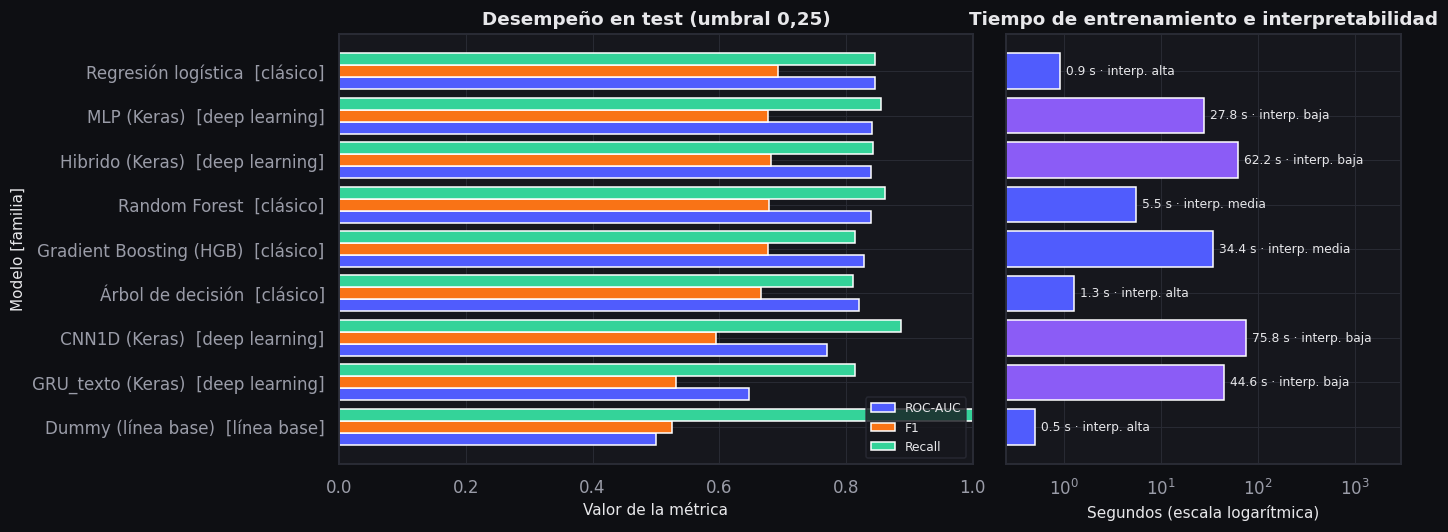

In [20]:
d = comparacion.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(d))
for i, (met, etiqueta) in enumerate([("roc_auc", "ROC-AUC"), ("f1", "F1"), ("recall", "Recall")]):
    ax[0].barh(y + (i - 1) * 0.27, d[met], height=0.27, color=SERIE[i], label=etiqueta)
ax[0].set(yticks=y, yticklabels=[f"{m}  [{f}]" for m, f in zip(d["modelo"], d["familia"])], xlim=(0, 1),
          title="Desempeño en test (umbral 0,25)", xlabel="Valor de la métrica", ylabel="Modelo [familia]")
ax[0].legend(fontsize=8, loc="lower right")
colores = [PALETA["ia"] if f == "deep learning" else PALETA["acento"] for f in d["familia"]]
ax[1].barh(y, d["tiempo_entrenamiento_s"], color=colores)
for yi, (t, interp) in enumerate(zip(d["tiempo_entrenamiento_s"], d["interpretabilidad"])):
    ax[1].text(t * 1.15, yi, f"{t:,.1f} s · interp. {interp}", va="center", fontsize=8, color=PALETA["texto"])
ax[1].set_xscale("log")
ax[1].set(yticks=y, yticklabels=[], title="Tiempo de entrenamiento e interpretabilidad",
          xlabel="Segundos (escala logarítmica)", xlim=(max(d["tiempo_entrenamiento_s"].min() / 2, 1e-3),
                                                        d["tiempo_entrenamiento_s"].max() * 40))
plt.show()
categorias = comparacion["modelo"].tolist()
figura_front("barras", "Clásicos vs Deep Learning · desempeño en test (umbral 0,25)",
             {"categorias": categorias, "familias": comparacion["familia"].tolist(),
              "series": [{"nombre": e, "valores": comparacion[m].round(4).tolist()}
                         for m, e in [("roc_auc", "ROC-AUC"), ("f1", "F1"), ("recall", "Recall")]]},
             ejes={"x": "Modelo", "y": "Valor de la métrica"}, clave="clasicos_vs_dl_metricas",
             opciones={"formato_y": "dec3", "color_por": "familia"})
figura_front("barras_h", "Clásicos vs Deep Learning · tiempo de entrenamiento",
             {"categorias": categorias, "familias": comparacion["familia"].tolist(),
              "interpretabilidad": comparacion["interpretabilidad"].tolist(),
              "series": [{"nombre": "Segundos", "valores": comparacion["tiempo_entrenamiento_s"].round(2).tolist()}]},
             ejes={"x": "Segundos (escala logarítmica)", "y": "Modelo"}, clave="clasicos_vs_dl_tiempo",
             opciones={"escala_log": True, "formato_x": "num", "color_por": "familia"})

**Interpretación.** La regresión logística sigue primera en AUC (0,8459) y F1 (0,6922) y se entrena en 0,9 s.
El mejor modelo de Deep Learning, el MLP, queda 0,004 de AUC por debajo (0,8419), con F1 0,6778, recall
0,8560 y 27,8 s de entrenamiento (unas 30 veces más), además de interpretabilidad baja. El híbrido (0,8399)
y el Random Forest (0,8397) prácticamente empatan con el MLP. La CNN 1D (0,7709) y la GRU de solo texto
(0,6466) quedan por debajo de todos los clásicos, aunque superan a la línea base (0,5). En recall al umbral
0,25 todos los modelos con señal quedan entre 0,81 y 0,89; la línea base llega a 1,0 solo porque clasifica a
todos como impago. Los tiempos son de una sola ejecución en una máquina compartida: indican el orden de
magnitud, no una medición fina.

## 9. Resultados para el front y la comparación global

In [21]:
res = ResultadosDL(notebook="06_red_neuronal.ipynb", umbral_metricas=UMBRAL, modelos=filas_dl,
                   curvas={f"{n} (Keras)": curvas(y_te, p) for n, p in p_test.items()},
                   backend=dl.version_backend(), historiales={f"{n} (Keras)": entrenos[n]["historial"] for n in redes},
                   arquitecturas={f"{n} (Keras)": dl.arquitectura(m) for n, m in redes.items()},
                   mejor_red=f"{MEJOR} (Keras)")
ruta_res = guardar_resultados(res, "resultados_dl")
mejor_dl = tabla_test["roc_auc"].idxmax()
mejor_global = comparacion.iloc[0]
texto_clasicos = (f"El mejor modelo de toda la tabla es **{mejor_global['modelo']}** ({mejor_global['familia']}, AUC "
                  f"{mejor_global['roc_auc']:.4f}, entrenado en {mejor_global['tiempo_entrenamiento_s']:.1f} s)."
                  if clasicos is not None else "Falta `resultados_clasicos.json` para la comparación con los clásicos.")
display(Markdown(
    f"**Resumen calculado.** Backend: {res.backend}. Mejor red por AUC de validación: **{MEJOR}** "
    f"({entrenos[MEJOR]['val_auc']:.4f}); en test, la red con mayor AUC es **{mejor_dl}** "
    f"(AUC {tabla_test.loc[mejor_dl, 'roc_auc']:.4f}, F1 {tabla_test.loc[mejor_dl, 'f1']:.4f}, recall "
    f"{tabla_test.loc[mejor_dl, 'recall']:.4f}). La GRU que solo ve el texto llega a AUC "
    f"{tabla_test.loc['GRU_texto', 'roc_auc']:.4f}. {texto_clasicos} Tiempos de las redes: "
    + ", ".join(f"{n} {entrenos[n]['duracion_s']:.1f} s" for n in redes)
    + f". Artefactos: `{ruta(destino)}` y `{ruta(ruta_res)}`."))

**Resumen calculado.** Backend: tensorflow 2.20.0. Mejor red por AUC de validación: **Hibrido** (0.8576); en test, la red con mayor AUC es **MLP** (AUC 0.8419, F1 0.6778, recall 0.8560). La GRU que solo ve el texto llega a AUC 0.6466. El mejor modelo de toda la tabla es **Regresión logística** (clásico, AUC 0.8459, entrenado en 0.9 s). Tiempos de las redes: MLP 27.8 s, CNN1D 75.8 s, GRU_texto 44.6 s, Hibrido 62.2 s. Artefactos: `Back/models/red_neuronal.keras` y `Back/models/resultados_dl.json`.

## Conclusiones

1. **Se entrenaron y evaluaron en test cuatro redes con TensorFlow 2.20 y Keras 3** (IA3.2, IA3.E2): MLP,
   CNN 1D, GRU bidireccional sobre el texto e híbrido texto + tabular (API funcional). Todas usan
   `class_weight`, EarlyStopping (restaura los mejores pesos) y ModelCheckpoint sobre el AUC de validación, con
   el preprocesamiento y el vocabulario ajustados solo con la partición de ajuste.
2. **Sobreajuste.** Es leve y queda controlado en el MLP y el híbrido: la validación se estanca mientras el
   entrenamiento sigue subiendo, y EarlyStopping restaura las épocas 20 y 16. En la GRU es temprano (mejor
   época 4). En la CNN no aparece: todavía no convergía al llegar al tope de 30 épocas.
3. **Desempeño en test (umbral 0,25).** MLP: AUC 0,8419 y F1 0,6778. Híbrido: 0,8399 y 0,6815. CNN 1D: AUC
   0,7709. GRU de texto: AUC 0,6466. El texto tiene señal propia pero débil, y en test no mejora al modelo
   tabular.
4. **Clásicos vs Deep Learning (IA3.3).** Ninguna red supera a la regresión logística (AUC 0,8459, F1 0,6922,
   0,9 s, interpretabilidad alta). La mejor red queda a la par del Random Forest y por encima del boosting en AUC,
   pero tarda unas 30 veces más que la logística en entrenar y pierde la explicación por coeficientes, que en crédito es un
   requisito. Con datos tabulares de este tamaño (9.600 filas de train y 38 columnas transformadas), lo
   recomendable es mantener un modelo clásico como modelo servido. Las redes quedan como evidencia
   comparativa.
5. **Calibración.** `class_weight` infla las probabilidades. Corregir el prior con la prevalencia de train,
   sin usar test, mejora el Brier y el F1 de todas las redes; en el MLP, el Brier pasa de 0,1623 a 0,1509 y el
   F1 de 0,6432 a 0,6778. Una red entrenada con pesos de clase debe corregirse antes de aplicarle umbrales de
   costo.
6. **Artefactos.** `red_neuronal.keras` guarda el híbrido, la red con mejor AUC de validación (0,8576); al
   recargarlo reproduce las mismas probabilidades. `resultados_dl.json` guarda las métricas, las curvas, los
   historiales por época y las arquitecturas. El `.keras` recibe dos entradas: la matriz tabular ya
   transformada por `dl.preprocesador_tabular()`, que no viaja dentro del archivo, y el texto normalizado.